Imports


In [433]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import numpy as np
# from IPython.core.interactiveshell import InteractiveShell
# InteractiveShell.ast_node_interactivity = "all"
from collections import Counter




Getting Dataset and removing ID

In [434]:
df = pd.read_csv("../Datasets/mpii_human_pose.csv")

df = df.drop(columns=["ID"])
# df.set_index('NAME', inplace=True)

df.head(5)


,NAME,r ankle_X,r ankle_Y,r knee_X,r knee_Y,r hip_X,r hip_Y,l hip_X,l hip_Y,l knee_X,...,r shoulder_Y,l shoulder_X,l shoulder_Y,l elbow_X,l elbow_Y,l wrist_X,l wrist_Y,Scale,Activity,Category
0,015601864.jpg,620,394,616,269,573,185,647,188,661,...,167,692,185,693,240,688,313,3.021046,curling,sports
1,015599452.jpg,-1,-1,-1,-1,806,543,720,593,-1,...,281,719,299,711,516,545,466,5.641276,curling,sports
2,005808361.jpg,804,711,816,510,908,438,1040,454,906,...,253,1067,253,1167,353,1142,478,4.718488,curling,sports
3,086617615.jpg,301,461,305,375,201,340,294,342,335,...,261,314,264,327,320,362,346,2.681349,curling,sports
4,060111501.jpg,980,322,896,318,865,248,943,226,948,...,147,923,123,995,163,961,223,3.806403,curling,sports


In [435]:
folder_path = f'../Datasets/images'
image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg'))]
intersection = set(image_files).intersection(set(df["NAME"]))
df = df[df["NAME"].isin(intersection)]

df.shape

(17372, 36)

Percentage of NaNs

In [436]:
np.round(df.isnull().mean() * 100,1)


NAME            0.0
r ankle_X       0.0
r ankle_Y       0.0
r knee_X        0.0
r knee_Y        0.0
r hip_X         0.0
r hip_Y         0.0
l hip_X         0.0
l hip_Y         0.0
l knee_X        0.0
l knee_Y        0.0
l ankle_X       0.0
l ankle_Y       0.0
pelvis_X        0.0
pelvis_Y        0.0
thorax_X        0.0
thorax_Y        0.0
upper neck_X    0.0
upper neck_Y    0.0
head top_X      0.0
head top_Y      0.0
r wrist_X       0.0
r wrist_Y       0.0
r elbow_X       0.0
r elbow_Y       0.0
r shoulder_X    0.0
r shoulder_Y    0.0
l shoulder_X    0.0
l shoulder_Y    0.0
l elbow_X       0.0
l elbow_Y       0.0
l wrist_X       0.0
l wrist_Y       0.0
Scale           0.0
Activity        0.0
Category        0.0
dtype: float64

Adding Width and Height to the dataframe

In [437]:
image_sizes = {}

for file in df["NAME"]:
    image_path = os.path.join(folder_path, file)
    if os.path.exists(image_path):
        with Image.open(image_path) as img:
            image_sizes[file] = (img.width, img.height)
            
df["Width"] = df["NAME"].map(lambda x: image_sizes.get(x, (None, None))[0])
df["Height"] = df["NAME"].map(lambda x: image_sizes.get(x, (None, None))[1])

df.head(10)

,NAME,r ankle_X,r ankle_Y,r knee_X,r knee_Y,r hip_X,r hip_Y,l hip_X,l hip_Y,l knee_X,...,l shoulder_Y,l elbow_X,l elbow_Y,l wrist_X,l wrist_Y,Scale,Activity,Category,Width,Height
0,015601864.jpg,620,394,616,269,573,185,647,188,661,...,185,693,240,688,313,3.021046,curling,sports,1280,720
1,015599452.jpg,-1,-1,-1,-1,806,543,720,593,-1,...,299,711,516,545,466,5.641276,curling,sports,1280,720
2,005808361.jpg,804,711,816,510,908,438,1040,454,906,...,253,1167,353,1142,478,4.718488,curling,sports,1280,720
3,086617615.jpg,301,461,305,375,201,340,294,342,335,...,264,327,320,362,346,2.681349,curling,sports,1280,720
4,060111501.jpg,980,322,896,318,865,248,943,226,948,...,123,995,163,961,223,3.806403,curling,sports,1280,720
5,070807258.jpg,461,398,509,335,517,218,570,203,-1,...,265,636,356,621,417,2.400120,curling,sports,1280,720
6,002058449.jpg,918,456,659,518,713,413,979,288,1222,...,247,1112,384,1012,489,8.280870,curling,sports,1280,720
7,021233911.jpg,-1,-1,355,408,269,354,432,333,464,...,147,492,259,413,321,3.781047,sitting quietly,inactivity quiet/light,640,480
8,018182497.jpg,325,349,341,327,326,302,385,277,409,...,187,406,218,374,258,3.523671,sitting quietly,inactivity quiet/light,640,480
9,018340451.jpg,392,390,388,300,289,296,302,283,395,...,187,320,262,362,276,1.949178,"sitting, talking in person, on the phone, comp...",miscellaneous,854,480


In [438]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17372 entries, 0 to 17371
Data columns (total 38 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   NAME          17372 non-null  object 
 1   r ankle_X     17372 non-null  int64  
 2   r ankle_Y     17372 non-null  int64  
 3   r knee_X      17372 non-null  int64  
 4   r knee_Y      17372 non-null  int64  
 5   r hip_X       17372 non-null  int64  
 6   r hip_Y       17372 non-null  int64  
 7   l hip_X       17372 non-null  int64  
 8   l hip_Y       17372 non-null  int64  
 9   l knee_X      17372 non-null  int64  
 10  l knee_Y      17372 non-null  int64  
 11  l ankle_X     17372 non-null  int64  
 12  l ankle_Y     17372 non-null  int64  
 13  pelvis_X      17372 non-null  int64  
 14  pelvis_Y      17372 non-null  int64  
 15  thorax_X      17372 non-null  int64  
 16  thorax_Y      17372 non-null  int64  
 17  upper neck_X  17372 non-null  float64
 18  upper neck_Y  17372 non-nu


There are 6141 images with at least 1 missing member

In [439]:
filtered_df = df[df.eq(-1).any(axis=1)]
filtered_df.shape[0]

6141

Visualizing Keypoints

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_17228\1238266017.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(keypoints[i], keypoints[i+1], c='r', marker='x')


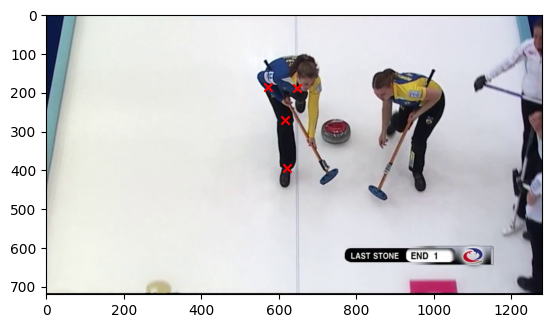

In [440]:

# filtered_data = df[(df[['r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y']] != -1).all(axis=1)]

# Helper function to visualize keypoints
def visualize_keypoints(image_path, keypoints):
    img = cv2.imread(image_path)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    
    # Draw keypoints
    for i in range(0, len(keypoints), 2):
        plt.scatter(keypoints[i], keypoints[i+1], c='r', marker='x')
    plt.show()

# Example: Visualize keypoints for a random image in the subset
sample_image = df.iloc[0]["NAME"]
sample_keypoints = df.iloc[0][['r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y', 'r hip_X', 'r hip_Y',
                                          'l hip_X', 'l hip_Y']]  # Select relevant keypoints
visualize_keypoints(f'../Datasets/images/{sample_image}', sample_keypoints)

Removing all rows with -1 for the sake of testing


In [441]:
# df= df[(df != -1).all(axis=1)]
df["Category"].unique()

array(['sports', 'inactivity quiet/light', 'miscellaneous', 'occupation',
       'water activities', 'home activities', 'lawn and garden',
       'religious activities', 'winter activities',
       'conditioning exercise', 'bicycling', 'fishing and hunting',
       'dancing', 'walking', 'running', 'self care', 'home repair',
       'music playing', 'transportation', 'volunteer activities', '[]'],
      dtype=object)

Amount of missing members, per column

In [442]:
count_per_column = (df == -1).sum()
count_per_column.sort_values(ascending=True, inplace=True)
count_per_column

NAME               0
Category           0
Activity           0
Height             0
Width              0
Scale              0
r shoulder_X      29
r shoulder_Y      29
l shoulder_X      33
l shoulder_Y      33
upper neck_X      58
thorax_X          58
upper neck_Y      58
thorax_Y          58
head top_X        59
head top_Y        60
l elbow_X         68
l elbow_Y         68
r elbow_Y         83
r elbow_X         83
r wrist_Y        148
r wrist_X        148
l wrist_Y        161
l wrist_X        161
l hip_X          429
l hip_Y          429
r hip_Y          463
r hip_X          463
pelvis_X         509
pelvis_Y         509
l knee_Y        3303
l knee_X        3303
r knee_Y        3343
r knee_X        3343
l ankle_X       5662
l ankle_Y       5662
r ankle_X       5705
r ankle_Y       5705
dtype: int64

In [443]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
r ankle_X,17372.0,427.772680,403.733806,-1.000000,-1.000000,390.000000,707.000000,1873.000000
r ankle_Y,17372.0,389.478414,319.773273,-1.000000,-1.000000,425.000000,625.000000,1108.000000
r knee_X,17372.0,503.829150,376.437796,-1.000000,219.750000,491.000000,751.000000,1910.000000
r knee_Y,17372.0,417.321207,266.223505,-1.000000,274.000000,442.000000,598.000000,1152.000000
r hip_X,17372.0,605.682362,336.443841,-1.000000,353.000000,574.000000,816.000000,1888.000000
r hip_Y,17372.0,443.063378,197.270991,-1.000000,312.000000,417.000000,559.000000,1077.000000
l hip_X,17372.0,646.921656,343.793741,-1.000000,392.000000,615.000000,863.000000,1908.000000
l hip_Y,17372.0,443.867545,196.410822,-1.000000,312.000000,418.000000,559.000000,1087.000000
l knee_X,17372.0,541.228241,392.865655,-1.000000,253.000000,532.000000,800.000000,1916.000000
l knee_Y,17372.0,416.992171,264.586203,-1.000000,276.000000,441.000000,593.000000,1170.000000


In [444]:
# df.sort_values(by="Height", ascending=True).head(5)

Largest X point is 1921
 
Largest Y point is 1170 

In [445]:
df.min()

NAME                                            000001163.jpg
r ankle_X                                                  -1
r ankle_Y                                                  -1
r knee_X                                                   -1
r knee_Y                                                   -1
r hip_X                                                    -1
r hip_Y                                                    -1
l hip_X                                                    -1
l hip_Y                                                    -1
l knee_X                                                   -1
l knee_Y                                                   -1
l ankle_X                                                  -1
l ankle_Y                                                  -1
pelvis_X                                                   -1
pelvis_Y                                                   -1
thorax_X                                                   -1
thorax_Y

In [446]:
df.max()

NAME                099992483.jpg
r ankle_X                    1873
r ankle_Y                    1108
r knee_X                     1910
r knee_Y                     1152
r hip_X                      1888
r hip_Y                      1077
l hip_X                      1908
l hip_Y                      1087
l knee_X                     1916
l knee_Y                     1170
l ankle_X                    1914
l ankle_Y                    1098
pelvis_X                     1875
pelvis_Y                     1076
thorax_X                     1873
thorax_Y                      995
upper neck_X            1866.1252
upper neck_Y             986.0035
head top_X              1915.4455
head top_Y              1010.4663
r wrist_X                    1905
r wrist_Y                    1094
r elbow_X                    1906
r elbow_Y                    1059
r shoulder_X                 1915
r shoulder_Y                 1033
l shoulder_X                 1912
l shoulder_Y                  956
l elbow_X     

In [447]:
df[["NAME", "upper neck_Y"]].sort_values(by='upper neck_Y', ascending=True).head(6)

,NAME,upper neck_Y
584,001971054.jpg,-8.0614
1560,091328695.jpg,-5.9819
15576,081575159.jpg,-5.0281
1667,010926421.jpg,-4.2650
11709,096725462.jpg,-3.1751
14357,071210893.jpg,-1.0000


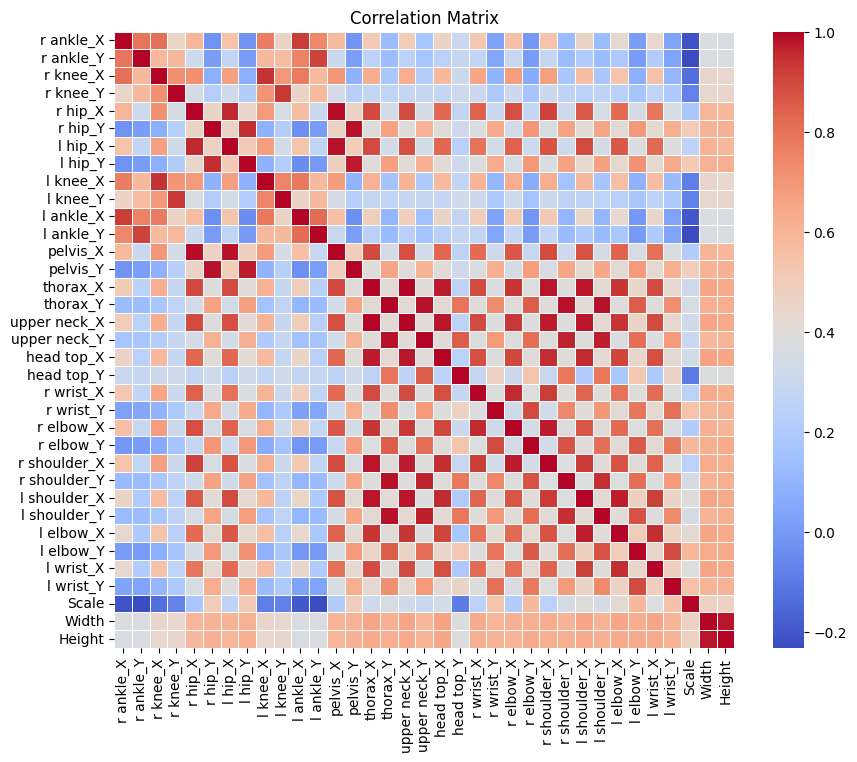

In [448]:

numeric_df = df.select_dtypes(include=['number'])
coor_matr = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(coor_matr, annot=False, cmap='coolwarm', fmt='.2f', linewidth=0.5)
plt.title('Correlation Matrix')
plt.show()

Número de membros não existentes por membro

In [449]:
count_neg_ones = df.apply(lambda col: (col == -1).sum())
count_neg_ones

NAME               0
r ankle_X       5705
r ankle_Y       5705
r knee_X        3343
r knee_Y        3343
r hip_X          463
r hip_Y          463
l hip_X          429
l hip_Y          429
l knee_X        3303
l knee_Y        3303
l ankle_X       5662
l ankle_Y       5662
pelvis_X         509
pelvis_Y         509
thorax_X          58
thorax_Y          58
upper neck_X      58
upper neck_Y      58
head top_X        59
head top_Y        60
r wrist_X        148
r wrist_Y        148
r elbow_X         83
r elbow_Y         83
r shoulder_X      29
r shoulder_Y      29
l shoulder_X      33
l shoulder_Y      33
l elbow_X         68
l elbow_Y         68
l wrist_X        161
l wrist_Y        161
Scale              0
Activity           0
Category           0
Width              0
Height             0
dtype: int64

Aqui em baixo temos predominância de valores pares, indica que possivelmente são imagens em que não aparecem ambas as pernas, ou braços, etc

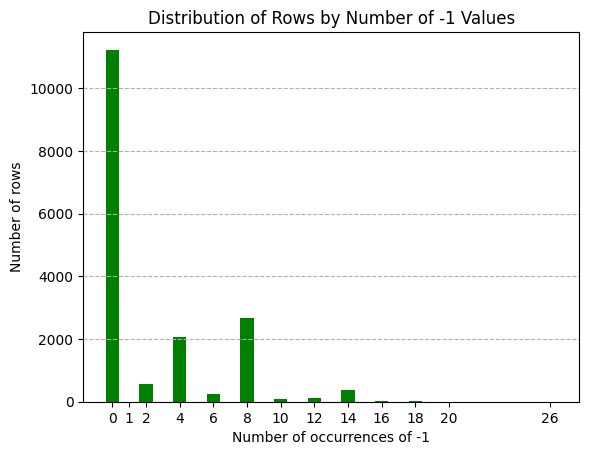

In [450]:
count_minus_one = (df == -1).sum(axis=1)
frequency = count_minus_one.value_counts().sort_index()
plt.bar(frequency.index, frequency.values, color='green')
plt.xlabel('Number of occurrences of -1')
plt.ylabel('Number of rows')
plt.title('Distribution of Rows by Number of -1 Values')
plt.xticks(frequency.index)
plt.grid(axis='y', linestyle='--', alpha=1)
plt.show()

Value distribution for each limb, if we remove the -1's we get clearer graphs

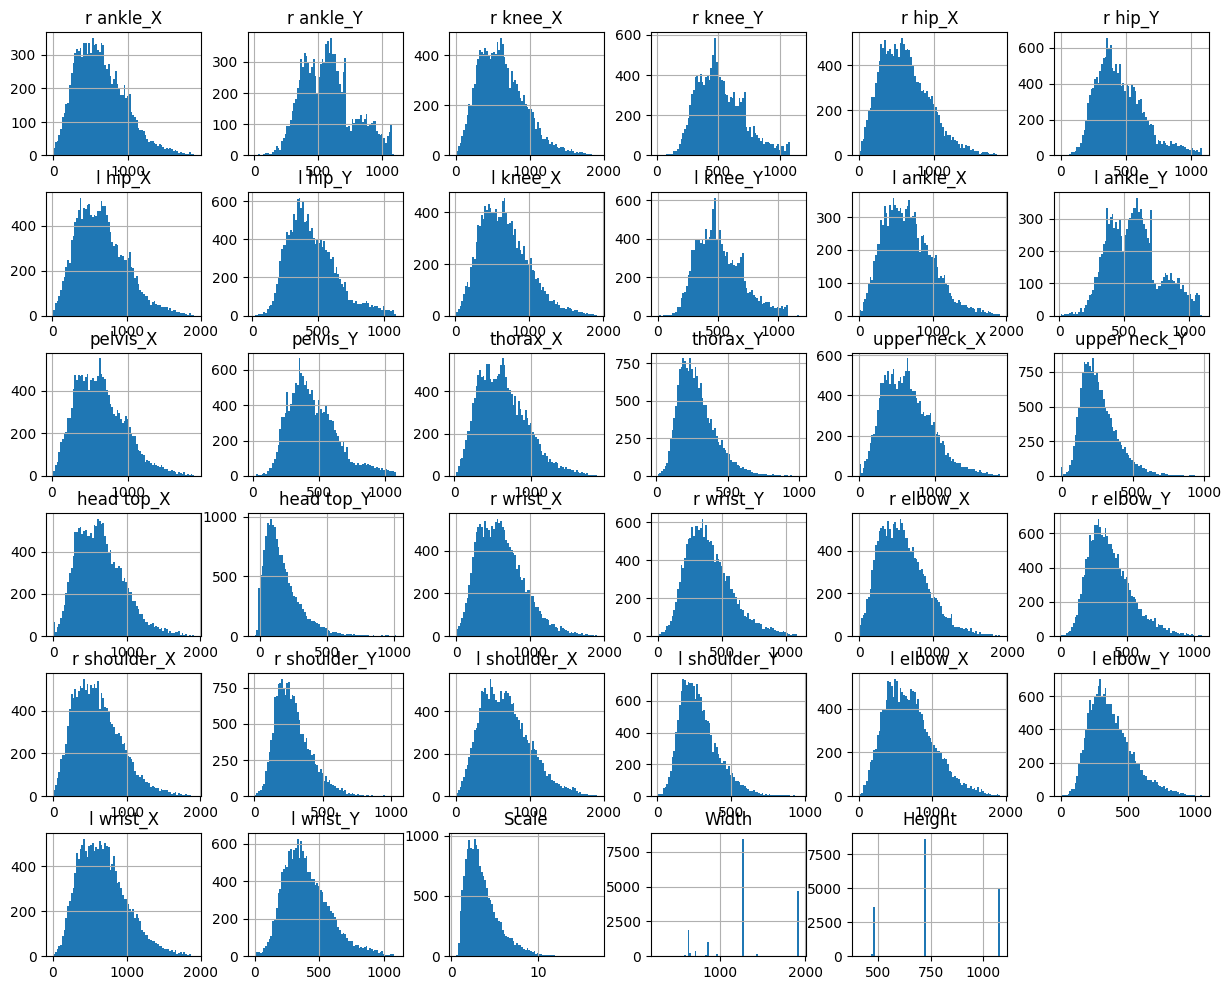

In [451]:
# histdf = df.drop(columns=["ID"])
histdf = df.copy(deep=True)
int_cols = histdf.select_dtypes(include='int')

# Keep only non-negative values in integer columns
histdf[int_cols.columns] = int_cols[int_cols >= 0]

# Plot histogram
histdf.hist(figsize=(15, 12), bins=80)
plt.title("Features Distribution (No Negatives in Int Columns)")
plt.show()

In [452]:
# keypoint_columns = df.select_dtypes(include='number')
# keypoint_columns = keypoint_columns.drop(columns=["Scale"])
# # keypoint_columns = keypoint_columns.columns
# keypoint_columns.columns

In [455]:
df

,NAME,r ankle_X,r ankle_Y,r knee_X,r knee_Y,r hip_X,r hip_Y,l hip_X,l hip_Y,l knee_X,...,l shoulder_Y,l elbow_X,l elbow_Y,l wrist_X,l wrist_Y,Scale,Activity,Category,Width,Height
0,015601864.jpg,620,394,616,269,573,185,647,188,661,...,185,693,240,688,313,3.021046,curling,sports,1280,720
1,015599452.jpg,-1,-1,-1,-1,806,543,720,593,-1,...,299,711,516,545,466,5.641276,curling,sports,1280,720
2,005808361.jpg,804,711,816,510,908,438,1040,454,906,...,253,1167,353,1142,478,4.718488,curling,sports,1280,720
3,086617615.jpg,301,461,305,375,201,340,294,342,335,...,264,327,320,362,346,2.681349,curling,sports,1280,720
4,060111501.jpg,980,322,896,318,865,248,943,226,948,...,123,995,163,961,223,3.806403,curling,sports,1280,720
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17367,033474347.jpg,876,461,815,380,779,296,742,303,706,...,223,674,286,631,260,2.003677,pushing car,transportation,1280,720
17368,082650067.jpg,1038,656,950,504,903,328,831,337,811,...,220,704,332,675,269,3.235820,pushing car,transportation,1280,720
17369,072772110.jpg,562,617,558,539,553,452,511,458,529,...,378,470,411,461,414,1.494952,pushing car,transportation,1280,720
17370,039361034.jpg,496,377,466,322,510,278,540,280,558,...,251,436,293,410,325,1.459468,pushing car,transportation,720,480


In [469]:
subset = df[(df["Width"] == 1920) & (df["Height"] == 1080)]
# subset = df[0]

def plot_body_part(body_part):
	x_coords = [col for col in subset.columns if col.endswith(body_part + '_X')]
	y_coords = [col for col in subset.columns if col.endswith(body_part + '_Y')]

	plt.figure(figsize=(8, 6))

	# Plot each point and label it
	for x, y in zip(x_coords, y_coords):
		body_part = x[:-2]  # Remove '_X' suffix to get the body part
		plt.scatter(subset[x], subset[y], label=body_part)
		plt.text(subset[x].iloc[0], subset[y].iloc[0] + 20, body_part, fontsize=9, ha='center')

	# Set axis limits to match 1920x1080 resolution
	plt.xlim(0, 1920)
	plt.ylim(1080, 0)

	# Add plot details
	plt.title("Body Part Coordinates (1920x1080)")
	plt.xlabel("X Coordinate")
	plt.ylabel("Y Coordinate")
	plt.axhline(0, color='black', linewidth=0.1, linestyle='--')
	plt.axvline(0, color='black', linewidth=0.1, linestyle='--')
	plt.grid(True)
	plt.legend(loc='upper right', fontsize=8)

	# Show the plot
	plt.show()
 


Ocorrences of wrist points

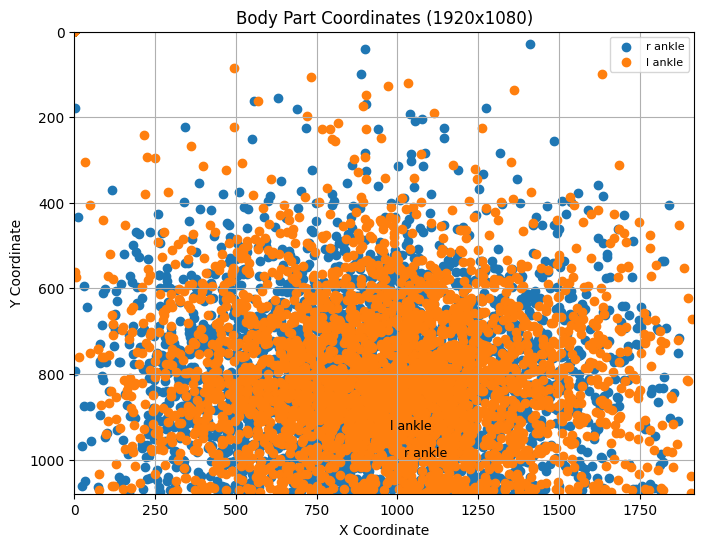

In [477]:
plot_body_part('ankle')

Ocorrences of knee points

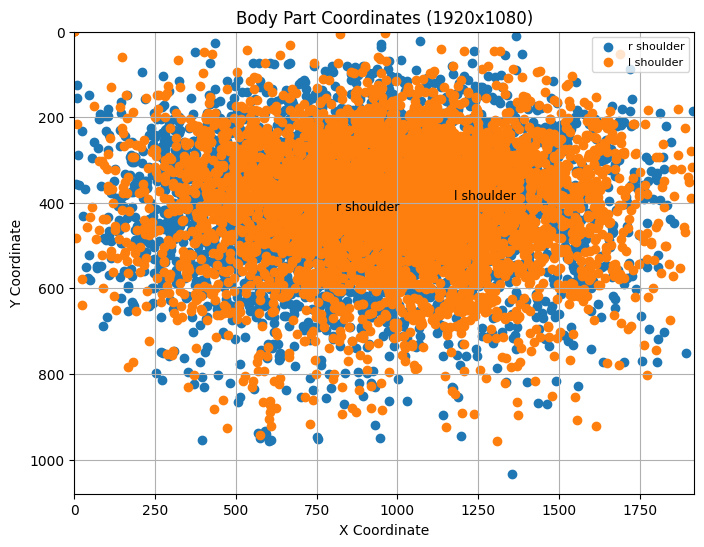

In [474]:
plot_body_part('shoulder')

In [417]:
df["Category"].unique()

array(['sports', 'inactivity quiet/light', 'miscellaneous', 'occupation',
       'water activities', 'home activities', 'lawn and garden',
       'religious activities', 'winter activities',
       'conditioning exercise', 'bicycling', 'fishing and hunting',
       'dancing', 'walking', 'running', 'self care', 'home repair',
       'music playing', 'transportation', 'volunteer activities', '[]'],
      dtype=object)

In [ ]:
df.columns

Index(['NAME', 'r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y', 'r hip_X',
       'r hip_Y', 'l hip_X', 'l hip_Y', 'l knee_X', 'l knee_Y', 'l ankle_X',
       'l ankle_Y', 'pelvis_X', 'pelvis_Y', 'thorax_X', 'thorax_Y',
       'upper neck_X', 'upper neck_Y', 'head top_X', 'head top_Y', 'r wrist_X',
       'r wrist_Y', 'r elbow_X', 'r elbow_Y', 'r shoulder_X', 'r shoulder_Y',
       'l shoulder_X', 'l shoulder_Y', 'l elbow_X', 'l elbow_Y', 'l wrist_X',
       'l wrist_Y', 'Scale', 'Activity', 'Category', 'Width', 'Height'],
      dtype='object')

Biggest Scale Images
 

<img src="../Datasets/Images/068162750.jpg" alt="title" width="300">  
<img src="../Datasets/Images/038440893.jpg" alt="title" width="300">  
<img src="../Datasets/Images/089881109.jpg" alt="title" width="300">  



Smallest Scale Images

<img src="../Datasets/Images/059907151.jpg" alt="title" width="300">  
<img src="../Datasets/Images/028418430.jpg" alt="title" width="300">  
<img src="../Datasets/Images/058219875.jpg" alt="title" width="300">  

It seems that the Scale depends on the people proximity, propably calculated with the distance between some points

In [419]:
df[["NAME", "Scale"]].sort_values(by="Scale", ascending=True).head(10)

,NAME,Scale
13981,059907151.jpg,0.544118
3329,028418430.jpg,0.600000
1574,058219875.jpg,0.600000
13975,013590738.jpg,0.614700
12960,054577715.jpg,0.633618
2745,039768441.jpg,0.679247
1889,098114373.jpg,0.679671
3195,030246632.jpg,0.686417
13974,003286273.jpg,0.697653
1079,041102847.jpg,0.715989


Image Analysis

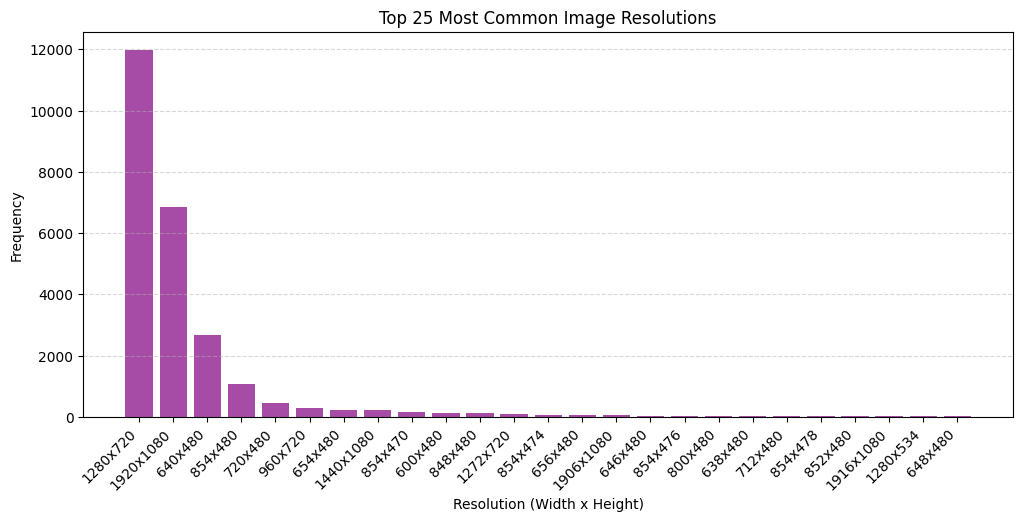

In [420]:
resolution_counts = Counter()

for file in image_files:
    with Image.open(os.path.join(folder_path, file)) as img:
        resolution_counts[(img.width, img.height)] += 1

# Get the 20 most common resolutions
top_resolutions = resolution_counts.most_common(25)

# Unpack data
res_values, res_frequencies = zip(*top_resolutions) if top_resolutions else ([], [])

# Convert (width, height) tuples to readable format
res_labels = [f"{w}x{h}" for w, h in res_values]

# Plot Top 20 Resolutions
plt.figure(figsize=(12, 5))
plt.bar(res_labels, res_frequencies, color='purple', alpha=0.7)
plt.xlabel("Resolution (Width x Height)")
plt.ylabel("Frequency")
plt.title("Top 25 Most Common Image Resolutions")
plt.xticks(rotation=45, ha="right")  # Rotate for better readability
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

Minimum Width and Height

In [421]:
list(resolution_counts)
first_index = [el[0] for el in list(resolution_counts)]
second_index = [el[1] for el in list(resolution_counts)]
min_width = min(first_index)
min_height = min(second_index)
min_width, min_height



(272, 400)

Average Color per image

In [422]:
# def average_color(image_path):
#     img = Image.open(image_path)
#     return np.array(img).mean(axis=(0,1))  # Mean per channel (R, G, B)

# avg_colors = np.array([average_color(os.path.join(folder_path, f)) for f in image_files])

# print(f"Average RGB Color: {avg_colors.mean(axis=0)}")


Average Brightness of Dataset: 114.99 out o 255 - 44.7%

In [423]:
# # Function to compute brightness
# def compute_brightness(img):
#     img = img.convert("L")  # Convert to grayscale
#     return np.array(img).mean()  # Compute mean intensity

# # Compute brightness for each image
# brightness_values = []

# for file in image_files:
#     with Image.open(os.path.join(folder_path, file)) as img:
#         brightness_values.append(compute_brightness(img))

# # Compute average brightness of the dataset
# average_brightness = np.mean(brightness_values) if brightness_values else 0

# print(f"Average Brightness of Dataset: {average_brightness:.2f}")

Color Distribution

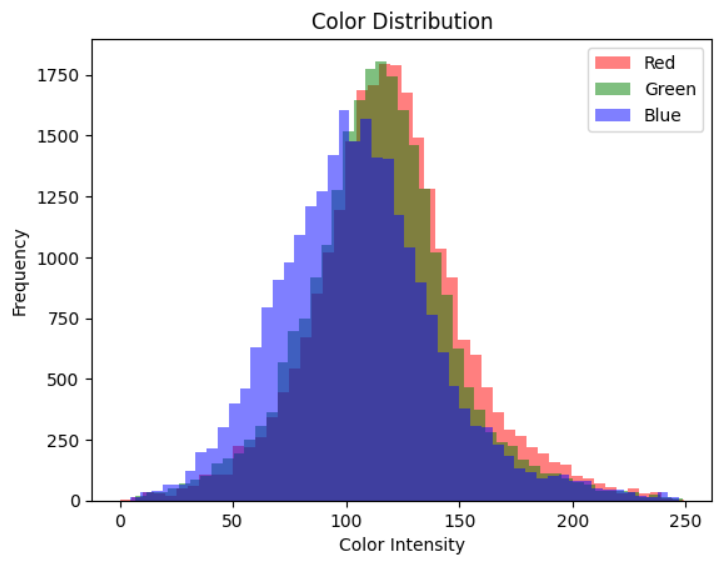

Retrieved Data:
 - 24984 Images
 - 6141 Images with at least 1 missing member (-1)
 - Image Width: 
	- Min: 272
	- Max: 1920
 - Image Height:
    - Min: 400
	- Max: 1080

 - Most common Resolutions: 1280x720; 1920x1080; 640x480

	Possible errors:
 	- head top_Y has 88 negative values (different than -1)
 	- upper neck_Y has 5 negative values (different than -1)
 	- In this images it looks like the members are not present, and it should have a -1
 	- l elbow_X has a 1921 value, in a 1920x1280 Image

 - Average Brightness of Dataset: 114.99 out o 255 - 44.7%
 - Color distribution seems balanced

In [424]:
subset = subset[(subset != -1).all(axis=1)]

subset.describe().T


,count,mean,std,min,25%,50%,75%,max
r ankle_X,3094.0,908.933743,349.957525,1.000000,672.000000,916.000000,1130.000000,1870.0000
r ankle_Y,3094.0,804.988365,163.461960,29.000000,707.250000,822.000000,925.000000,1108.0000
r knee_X,3094.0,901.842275,327.699620,30.000000,689.250000,905.500000,1103.750000,1847.0000
r knee_Y,3094.0,679.073045,138.445396,142.000000,597.250000,686.000000,774.000000,1071.0000
r hip_X,3094.0,911.497414,336.989187,37.000000,695.000000,923.000000,1117.000000,1854.0000
r hip_Y,3094.0,556.620556,136.771925,1.000000,472.000000,554.000000,638.000000,1073.0000
l hip_X,3094.0,950.945055,338.665629,23.000000,727.000000,970.000000,1164.000000,1906.0000
l hip_Y,3094.0,556.027149,135.550060,52.000000,471.000000,553.000000,636.750000,1040.0000
l knee_X,3094.0,959.250808,331.863784,75.000000,742.000000,973.500000,1176.000000,1912.0000
l knee_Y,3094.0,674.651584,140.322153,135.000000,589.250000,686.000000,770.000000,1053.0000


In [425]:
threshold = 3  # Typically, 3 standard deviations is considered an outlier

mean_scale = df['Scale'].mean()
std_scale = df['Scale'].std()

df['outlier'] = np.abs((df['Scale'] - mean_scale) / std_scale) > threshold
outliers = df[df['outlier']]
print(outliers)

                NAME  r ankle_X  r ankle_Y  r knee_X  r knee_Y  r hip_X  \
69     056127720.jpg         -1         -1        -1        -1     1822   
70     077096718.jpg         -1         -1        -1        -1       -1   
396    058991769.jpg         -1         -1        -1        -1      597   
458    089676542.jpg         -1         -1        -1        -1       -1   
480    041184091.jpg         -1         -1        -1        -1       -1   
...              ...        ...        ...       ...       ...      ...   
17175  051328836.jpg         -1         -1        -1        -1     1229   
17249  087035400.jpg         -1         -1        -1        -1       -1   
17251  070090668.jpg         -1         -1        -1        -1      677   
17257  027698978.jpg         -1         -1        -1        -1       -1   
17258  024214470.jpg         -1         -1        -1        -1       -1   

       r hip_Y  l hip_X  l hip_Y  l knee_X  ...  l elbow_X  l elbow_Y  \
69        1071     1648   

In [426]:
Q1 = df['Scale'].quantile(0.25)
Q3 = df['Scale'].quantile(0.75)
IQR = Q3 - Q1

df['outlier'] = (df['Scale'] < (Q1 - 1.5 * IQR)) | (df['Scale'] > (Q3 + 1.5 * IQR))
outliers = df[df['outlier']]
print(outliers)

                NAME  r ankle_X  r ankle_Y  r knee_X  r knee_Y  r hip_X  \
6      002058449.jpg        918        456       659       518      713   
38     018485446.jpg       1087        973       657       915      963   
69     056127720.jpg         -1         -1        -1        -1     1822   
70     077096718.jpg         -1         -1        -1        -1       -1   
195    035949115.jpg         -1         -1        -1        -1     1025   
...              ...        ...        ...       ...       ...      ...   
17281  021749318.jpg        659        646       234       733      553   
17282  098590383.jpg        888        817       556       693      876   
17283  071434253.jpg        978        764       643       640      975   
17284  082608207.jpg        876        727       528       603      866   
17290  012958454.jpg       1192        944      1121       677     1369   

       r hip_Y  l hip_X  l hip_Y  l knee_X  ...  l elbow_X  l elbow_Y  \
6          413      979   

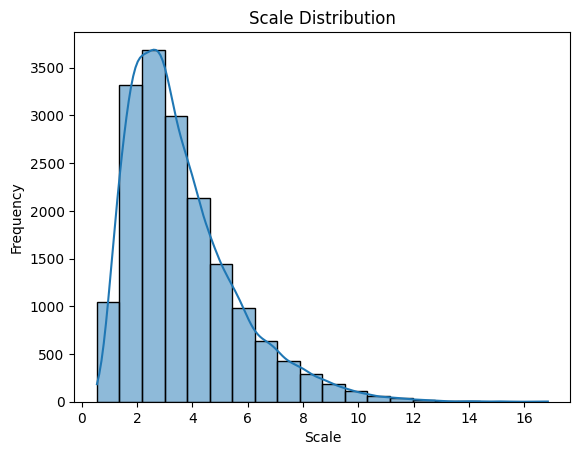

In [427]:
sns.histplot(data=df, x='Scale', bins=20, kde=True)
plt.xlabel('Scale')
plt.ylabel('Frequency')
plt.title('Scale Distribution')
plt.show()

In [428]:
from sklearn.ensemble import IsolationForest

features = ['r wrist_X', 'r wrist_Y', 'l wrist_X', 'l wrist_Y']  # Select relevant features
clf = IsolationForest(contamination=0.01, random_state=42)  # Adjust contamination level
subset['outlier'] = clf.fit_predict(subset[features]) == -1  # -1 means an outlier

outliers = subset[subset['outlier']]
print(outliers)


                NAME  r ankle_X  r ankle_Y  r knee_X  r knee_Y  r hip_X  \
111    097178208.jpg         88        611       122       600      126   
366    098727613.jpg        262        764       538       541      677   
660    003118314.jpg        128        607       149       485      162   
1386   019809763.jpg       1320        886      1508       966     1194   
1882   004997903.jpg        486        927       327       780      333   
2918   082006750.jpg        242        879       292       646      417   
3393   008058081.jpg        154        519       157       404      149   
5426   045566082.jpg        516        826       492       857      463   
5429   038306937.jpg        561        684       439       634      427   
5430   086909907.jpg        436        792       436       814      432   
5445   049565392.jpg        132        629       134       517      195   
6702   021508523.jpg         73       1064       112       862       76   
7214   029464890.jpg     

In [ ]:
subset = subset[(df != -1).all(axis=1)]
subset.describe().T


C:\Users\Utilizador\AppData\Local\Temp\ipykernel_17228\2156383961.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  subset = subset[(df != -1).all(axis=1)]


,count,mean,std,min,25%,50%,75%,max
r ankle_X,3094.0,908.933743,349.957525,1.000000,672.000000,916.000000,1130.000000,1870.0000
r ankle_Y,3094.0,804.988365,163.461960,29.000000,707.250000,822.000000,925.000000,1108.0000
r knee_X,3094.0,901.842275,327.699620,30.000000,689.250000,905.500000,1103.750000,1847.0000
r knee_Y,3094.0,679.073045,138.445396,142.000000,597.250000,686.000000,774.000000,1071.0000
r hip_X,3094.0,911.497414,336.989187,37.000000,695.000000,923.000000,1117.000000,1854.0000
r hip_Y,3094.0,556.620556,136.771925,1.000000,472.000000,554.000000,638.000000,1073.0000
l hip_X,3094.0,950.945055,338.665629,23.000000,727.000000,970.000000,1164.000000,1906.0000
l hip_Y,3094.0,556.027149,135.550060,52.000000,471.000000,553.000000,636.750000,1040.0000
l knee_X,3094.0,959.250808,331.863784,75.000000,742.000000,973.500000,1176.000000,1912.0000
l knee_Y,3094.0,674.651584,140.322153,135.000000,589.250000,686.000000,770.000000,1053.0000
